# Lecture 8: Overconfident Firms and the Investment Boom

**Lecture 8 of 9** · [Series index](README.md)

*This lecture builds on [Lecture 2: Cass-Koopmans with Capital and Labour Adjustment Costs](02_adjustment_costs.ipynb) and [Lecture 7: Bayesian Updating and Overconfidence](07_bayesian_overconfidence.ipynb). The series begins with [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb), which adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). The Newton solver is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0. This lecture is shared under the same licence.*

## Overview

[Lecture 7](07_bayesian_overconfidence.ipynb) modelled overprecision as a single distortion of Bayes' rule: an agent who believes its signal is $\kappa$ times more precise than it is. In an asset market, that made prices overreact to news and then reverse.

This lecture puts the same distortion inside a firm's investment decision, using the capital adjustment costs of [Lecture 2](02_adjustment_costs.ipynb). The question is the one Malmendier and Tate (2005) asked of real CEOs: what happens to investment when the people who decide it are too sure of their own reading of the news?

The setting is deliberately simple. Productivity jumps. Part of the jump is permanent and part will fade, but nobody can yet tell which part is which. A Bayesian manager splits the difference according to the relative variances. An overconfident manager reads more of the jump as permanent. Because capital is costly to adjust, both managers start building towards the capital stock they expect to need, and both learn the truth a few years later.

The plan is:

1. the evidence on overconfident managers and why investment is where it should matter,
2. the **signal-extraction problem**: separating a permanent from a transitory productivity change, and where $\kappa$ enters,
3. the firm's problem in a **small open economy**, and the **temporary-equilibrium** method for solving models in which beliefs and outcomes differ,
4. a **closed-form linear solution**: the investment boom, the bust that follows, and their size in terms of $\kappa$,
5. the fully **nonlinear** solution with Newton's method, checked against the closed form,
6. **who loses**: shareholders, workers and the economy as a whole, with a first-order transfer and a second-order efficiency loss, and
7. what changes when **everyone** is overconfident, in the closed economy of Lecture 2, where the boom disappears.

The last part is the main lesson. The macroeconomic effect of overconfidence depends on who holds it.

## Overconfident managers

### The evidence

- **Revealed beliefs.** Malmendier and Tate (2005) classify CEOs as overconfident when they keep deep-in-the-money stock options well past the point a diversified, risk-averse executive would exercise them, a bet on their own firm's prospects. These CEOs' investment is markedly more sensitive to the firm's cash flow. Malmendier and Tate (2008) find that the same CEOs make more acquisitions, and that markets react more negatively when they announce them.
- **Miscalibrated forecasts.** Ben-David, Graham and Harvey (2013) collected thousands of stock market forecasts from chief financial officers, each with an 80% confidence interval. The realised returns fell inside the intervals far less often than 80% of the time. Firms with more miscalibrated CFOs invested more and used more debt.
- **Expectations drive investment.** Gennaioli, Ma and Shleifer (2016) show that CFOs' expectations of their own firm's earnings growth predict investment plans and actual investment, even after controlling for Tobin's $q$ and other market measures, and that those expectations are too optimistic after good news.

### Why investment

Overconfidence about something you can reverse costlessly does little damage: you act on your belief and undo the action when you learn the truth. Investment is different. [Lecture 2](02_adjustment_costs.ipynb) made changing the capital stock quickly expensive, so a firm that builds on a mistaken forecast is stuck with its capital for years, and pays again to unwind it. Adjustment costs turn a mistake in beliefs into a persistent mistake in the capital stock.

## The information problem

### Permanent or transitory?

Productivity has been at its steady-state level, $A = 1$, and at date $0$ it jumps by $x$. The jump has two parts:

$$
A_t = 1 + \theta + \eta\, \mathbf{1}\{t < \tau\}
$$

- a **permanent** part $\theta$, and
- a **transitory** part $\eta$, which lasts for $\tau$ years and then disappears.

The firm observes the jump $x = \theta + \eta$ but not its two parts. It learns them at date $\tau$, when the transitory part ends and productivity settles at $1 + \theta$.

Its prior is that the two parts are independent, $\theta \sim N(0, \sigma_P^2)$ and $\eta \sim N(0, \sigma_T^2)$. This is the normal–normal problem of [Lecture 7](07_bayesian_overconfidence.ipynb): $x$ is a signal of $\theta$ with noise $\eta$. So the posterior mean of the permanent part is

$$
m = \mathbb{E}[\theta \mid x] = w\, x, \qquad w = \frac{\sigma_P^2}{\sigma_P^2 + \sigma_T^2} = \frac{\varrho}{1 + \varrho}, \qquad \varrho = \frac{\sigma_P^2}{\sigma_T^2}
$$

where $\varrho$ is the signal-to-noise ratio, and the posterior variance is $v = \sigma_P^2 \sigma_T^2 / (\sigma_P^2 + \sigma_T^2)$.

### The overconfident manager

An overconfident manager treats the jump as a more precise signal of the permanent part than it is, with perceived precision $\kappa / \sigma_T^2$. Exactly as before,

$$
\hat m = \hat w\, x, \qquad \hat w = \frac{\kappa \varrho}{1 + \kappa \varrho}
$$

With $\kappa > 1$, the manager reads too much of the jump as permanent. With $\kappa < 1$ it reads too little.

Throughout, we take $\sigma_P = \sigma_T$, so $\varrho = 1$ and $w = 0.5$, a jump of $x = 2\%$, and $\tau = 4$ years. With $\kappa = 4$, $\hat w = 0.8$: the overconfident manager expects productivity to settle 1.6% higher, the Bayesian 1%.

### The truth we compare against

We need a realised value of $\theta$ to compare outcomes. The natural choice is $\theta = m = w x$, the Bayesian's own forecast. Then the Bayesian is never surprised, and every difference between the paths is due to the overconfident manager's mistake. The section on who loses checks that averaging over all values of $\theta$ consistent with the information gives the same answer.

## The firm in a small open economy

### Why a small open economy

To isolate the manager's beliefs, everything else has to stay correct. So in this part of the lecture:

- the firm borrows and lends at a fixed **world interest rate** $r = 1/\beta - 1$, which households' beliefs cannot move,
- labour is supplied inelastically at $\bar n$, and the wage is its marginal product, and
- households hold correct beliefs, and own the firm.

This is the CGE modeller's fixed-rate-of-return closure, applied to a single sector. The last part of the lecture drops it.

### The firm's problem

Output is $Y_t = A_t k_t^\alpha \bar n^{1-\alpha}$ and the adjustment cost is the one from Lecture 2, $AC_t = \tfrac{\zeta}{2} k_t (g_t - 1)^2$ with $g_t = k_{t+1}/k_t$. Taking the wage as given, the firm pays out

$$
d_t = Y_t - w_t \bar n - I_t - AC_t, \qquad I_t = k_{t+1} - (1 - \delta) k_t
$$

and chooses $\{k_{t+1}\}$ to maximise $\sum_t (1+r)^{-t} d_t$ under its beliefs about $A_t$. The first-order condition for $k_{t+1}$ is the capital Euler equation of Lecture 2, with the household's discount factor replaced by the world interest rate:

$$
\boxed{\;1 + \zeta (g_t - 1) = \frac{\alpha \hat A_{t+1} k_{t+1}^{\alpha - 1} \bar n^{1-\alpha} + 1 - \delta + \tfrac{\zeta}{2}\left(g_{t+1}^2 - 1\right)}{1 + r}\;}
$$

where $\hat A$ is the productivity path the manager expects. The left side is **marginal $q$**, the value of one more unit of installed capital in units of goods: the cost of a new unit plus the marginal adjustment cost. The right side is next year's marginal product, plus the undepreciated unit, plus the adjustment cost saved next year by already having the capital, all discounted.

In the steady state $g = 1$ and $q = 1$, so $\alpha A (k/\bar n)^{\alpha - 1} = r + \delta$. A permanent rise of $\theta$ in productivity raises the steady-state capital stock by a factor $(1 + \theta)^{1/(1-\alpha)}$.

### Temporary equilibrium

The models in this series have all been **perfect foresight**: agents know the future path of everything, and the Newton routine solves for it as one stacked system. With beliefs that can be wrong, the path agents *plan* and the path that *happens* differ. The standard way to handle this is **temporary equilibrium** (Grandmont, 1977):

1. at date $0$, solve the stacked system under the manager's beliefs $\hat A$, starting from the current capital stock,
2. implement the plan for as long as beliefs don't change, here until date $\tau$,
3. at date $\tau$, when the truth is revealed, solve the stacked system again from the capital stock $k_\tau$ the plan has delivered, under the true productivity path, and
4. stitch the two segments together.

Each step is the same Newton solve as before. Only the initial condition and the productivity path change. This is also how the naive present-biased household of Lecture 6 was solved: plan, act for a period, re-plan.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

The Newton routine is the one used throughout the series, adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html).

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x

The calibration is that of Lecture 2: $\beta = 0.95$ (so $r = 5.26\%$), $\delta = 0.02$, $\alpha = 0.33$, $\zeta = 5$ and employment of one third of the time endowment. The unknowns are $\log k_1, \ldots, \log k_T$, with $k_{T+1}$ set to the steady state implied by the productivity level at the end of the horizon.

In [3]:
Firm = namedtuple('Firm', ['r', 'delta', 'alpha', 'zeta', 'n_bar', 'T', 'k_ss'])
Info = namedtuple('Info', ['x', 'varrho', 'tau'])


def get_firm(beta=0.95, delta=0.02, alpha=0.33, zeta=5.0, n_bar=1/3, T=150):
    r = 1 / beta - 1
    k_ss = n_bar * ((r + delta) / alpha) ** (1 / (alpha - 1))      # alpha (k/n)^(alpha-1) = r + delta, A = 1
    return Firm(r, delta, alpha, zeta, n_bar, T, k_ss)


def weights(kappa, info):
    # Bayesian and perceived weights on the observed jump (normal-normal updating)
    return info.varrho / (1 + info.varrho), kappa * info.varrho / (1 + kappa * info.varrho)


def mpk(A, k, f):
    return f.alpha * A * k ** (f.alpha - 1) * f.n_bar ** (1 - f.alpha)


def euler_residuals(x, A, k0, f):
    # x = log(k_1..k_T); A = productivity path A_0..A_T as the firm sees it
    k_end = f.k_ss * A[-1] ** (1 / (1 - f.alpha))
    k = jnp.concatenate([jnp.array([k0]), jnp.exp(x), jnp.array([k_end])])
    g = k[1:] / k[:-1]                                              # g_0..g_T
    lhs = 1 + f.zeta * (g[:-1] - 1)                                 # marginal q, t = 0..T-1
    rhs = (mpk(A[1:], k[1:-1], f) + 1 - f.delta + f.zeta / 2 * (g[1:] ** 2 - 1)) / (1 + f.r)
    return jnp.log(lhs) - jnp.log(rhs)


def solve_plan(A, k0, f):
    # The firm's optimal capital plan k_0..k_{T+1} from k0, given an expected productivity path.
    A = jnp.asarray(A)[:f.T + 1]
    k_end = f.k_ss * float(A[-1]) ** (1 / (1 - f.alpha))
    x0 = jnp.log(jnp.linspace(k0, k_end, f.T + 2)[1:-1])
    resid = lambda x: euler_residuals(x, A, k0, f)
    x = newton(resid, x0, tol=1e-12, max_iter=50)
    return np.concatenate([[k0], np.exp(np.asarray(x)), [k_end]]), float(jnp.max(jnp.abs(resid(x))))


def productivity(pre, post, n, tau):
    # 1 + pre before tau, 1 + post from tau on
    A = np.full(n, 1 + post)
    A[:tau] = 1 + pre
    return A

In [4]:
def temporary_equilibrium(kappa, info, f, theta=None):
    # Plan under the manager's beliefs, act until tau, then re-plan under the truth.
    w, w_hat = weights(kappa, info)
    theta = w * info.x if theta is None else theta            # default: the Bayesian forecast comes true
    n = f.T + info.tau + 2
    A_belief = productivity(info.x, w_hat * info.x, n, info.tau)
    A_true = productivity(info.x, theta, n, info.tau)
    k_plan, res1 = solve_plan(A_belief, f.k_ss, f)
    k_after, res2 = solve_plan(A_true[info.tau:], k_plan[info.tau], f)
    k = np.concatenate([k_plan[:info.tau], k_after])[:f.T + 2]
    return dict(k=k, k_plan=k_plan, A=A_true[:f.T + 1], A_belief=A_belief[:f.T + 1],
                residual=max(res1, res2), w_hat=w_hat, theta=theta)


def outcomes(path, f):
    # Realised quantities, prices and present values under the true productivity path.
    k, A = path['k'], path['A']
    Y = A * k[:-1] ** f.alpha * f.n_bar ** (1 - f.alpha)
    I = k[1:] - (1 - f.delta) * k[:-1]
    AC = f.zeta / 2 * k[:-1] * (k[1:] / k[:-1] - 1) ** 2
    wage_bill = (1 - f.alpha) * Y
    div = Y - wage_bill - I - AC
    disc = (1 + f.r) ** -np.arange(len(Y))
    return dict(path, Y=Y, I=I, AC=AC, q=1 + f.zeta * (k[1:] / k[:-1] - 1), div=div, wage_bill=wage_bill,
                V=disc @ div, PV_wages=disc @ wage_bill, W=disc @ (Y - I - AC))


f = get_firm()
info = Info(x=0.02, varrho=1.0, tau=4)
kappas = [0.25, 1.0, 4.0]
paths = {kap: outcomes(temporary_equilibrium(kap, info, f), f) for kap in kappas}
I_ss = f.delta * f.k_ss
print(f'k_ss = {f.k_ss:.4f}, r = {100 * f.r:.2f}%')
for kap, p in paths.items():
    print(f'kappa = {kap:4}: w_hat = {p["w_hat"]:.2f}, max |residual| = {p["residual"]:.1e}, '
          f'investment vs steady state (%) t = 0..7: {np.round(100 * (p["I"][:8] / I_ss - 1), 1)}')

k_ss = 3.1919, r = 5.26%
kappa = 0.25: w_hat = 0.20, max |residual| = 3.1e-15, investment vs steady state (%) t = 0..7: [4.9 3.8 2.7 1.6 4.7 4.5 4.3 4.1]
kappa =  1.0: w_hat = 0.50, max |residual| = 3.8e-15, investment vs steady state (%) t = 0..7: [7.1 6.2 5.3 4.4 4.2 4.  3.9 3.7]
kappa =  4.0: w_hat = 0.80, max |residual| = 4.2e-15, investment vs steady state (%) t = 0..7: [9.3 8.6 8.  7.3 3.7 3.6 3.4 3.3]


Before $\tau$, the overconfident manager invests more than the Bayesian, who in turn invests more than the underconfident manager. From $\tau$ on, the ranking reverses. The next section derives both facts, and their size, in closed form.

## The linear solution

### Linearising the Euler equation

Write $\hat k_t = \log(k_t / k_{ss})$ and $a_t = A_t - 1$ for deviations, so $g_t - 1 \approx \hat k_{t+1} - \hat k_t$ and, using $\alpha k^{\alpha-1}\bar n^{1-\alpha} = r + \delta$ in the steady state,

$$
\alpha A_{t+1} k_{t+1}^{\alpha - 1} \bar n^{1-\alpha} \approx (r + \delta)\left[1 + a_{t+1} - (1 - \alpha)\hat k_{t+1}\right]
$$

Substituting into the Euler equation, multiplying by $1 + r$ and keeping first-order terms ($g^2 - 1 \approx 2(g - 1)$):

$$
(1+r)\,\zeta\,(\hat k_{t+1} - \hat k_t) = (r+\delta)\left[a_{t+1} - (1-\alpha)\hat k_{t+1}\right] + \zeta\,(\hat k_{t+2} - \hat k_{t+1})
$$

or, collecting terms,

$$
\zeta\, \hat k_{t+2} - \left[\zeta(2 + r) + c\right] \hat k_{t+1} + \zeta(1+r)\, \hat k_t = -(r + \delta)\, a_{t+1}, \qquad c = (r+\delta)(1-\alpha)
$$

### The roots

The characteristic polynomial $\zeta \lambda^2 - [\zeta(2+r) + c]\lambda + \zeta(1+r)$ has two real roots, $\mu$ and $\nu$, with

$$
\mu\,\nu = 1 + r, \qquad \mu + \nu = 2 + r + \frac{c}{\zeta}
$$

Evaluating the polynomial at $\lambda = 1$ gives $-c < 0$, so one root is below one and one above: $0 < \mu < 1 < 1 + r < \nu$. The stable root $\mu$ governs how fast capital adjusts. Higher adjustment costs $\zeta$ push $\mu$ towards one: slower adjustment.

### The decision rule

Write the left side as $\zeta(\hat k_{t+2} - \mu \hat k_{t+1}) - \nu\,\zeta(\hat k_{t+1} - \mu \hat k_t)$ and define $z_t = \hat k_{t+1} - \mu \hat k_t$. Then $z_{t+1} - \nu z_t = -(r+\delta) a_{t+1}/\zeta$, and solving this unstable equation forwards gives

**Proposition 1 (decision rule).** To first order, the capital plan satisfies

$$
\boxed{\;\hat k_{t+1} = \mu\, \hat k_t + \frac{r + \delta}{\zeta\, \nu} \sum_{j=0}^{\infty} \nu^{-j}\, a_{t+1+j}\;}
$$

Capital moves part of the way towards where it was, at rate $\mu$, and is pushed by a discounted sum of **expected** future productivity, discounted at $\nu > 1 + r$. Expected productivity in the far future matters less than near-term productivity, both because of discounting and because the adjustment cost makes it pointless to build early for something far off.

*Check.* For a permanent change $a_t = a$, the long-run capital stock solves $\hat k^* = \mu \hat k^* + (r+\delta)a/(\zeta(\nu - 1))$, so $\hat k^* = (r+\delta)a / [\zeta(\nu-1)(1-\mu)]$. Expanding, $\zeta(\nu - 1)(1 - \mu) = \zeta(\mu + \nu) - \zeta - \zeta\mu\nu = c$, so $\hat k^* = a/(1-\alpha)$, the log-linear version of the steady-state result above.

### The boom

The two managers face the same productivity, $1 + x$, until $\tau$. They differ only in what they expect after $\tau$: $1 + \hat m$ against $1 + m$. Applying Proposition 1 to the difference between their plans, $\Delta \hat k_t$, with $\Delta a_s = \hat m - m$ for $s \geq \tau$ and zero before, the forcing term at date $t < \tau$ is

$$
\frac{r+\delta}{\zeta \nu}(\hat m - m)\sum_{j \geq \tau - 1 - t} \nu^{-j} = \frac{r + \delta}{\zeta(\nu - 1)}\, \nu^{-(\tau - 1 - t)}\, (\hat m - m)
$$

**Proposition 2 (overinvestment).** Before $\tau$, the overconfident manager's capital stock exceeds the Bayesian's by

$$
\boxed{\;\Delta \hat k_{t+1} = \frac{r + \delta}{\zeta(\nu - 1)}\,(\hat w - w)\, x \sum_{s=0}^{t} \mu^{t - s}\, \nu^{-(\tau - 1 - s)}, \qquad t = 0, \ldots, \tau - 1\;}
$$

The gap is proportional to $\hat w - w$, the overreaction to the signal, and to the size of the jump $x$. It **grows** as $\tau$ approaches, because the date at which the manager expects the extra productivity to matter is getting closer. It is larger when adjustment costs are small, because then building early is cheap.

### The bust

At $\tau$, the overconfident manager learns that productivity will settle at $1 + m$ and re-plans from a capital stock that is too high. From then on, both firms face the same forcing, so by Proposition 1 the difference obeys

$$
\Delta \hat k_{t+1} = \mu\, \Delta \hat k_t, \qquad t \geq \tau
$$

The excess capital decays at rate $\mu$. Investment is $I_t = k_{t+1} - (1-\delta)k_t$, so in deviations, $\hat I_t \approx [\hat k_{t+1} - (1-\delta)\hat k_t]/\delta$, and

**Proposition 3 (the bust).** After $\tau$, the investment gap is

$$
\boxed{\;\Delta \hat I_t = \frac{\mu - (1-\delta)}{\delta}\, \Delta \hat k_t, \qquad t \geq \tau\;}
$$

With adjustment costs large enough that $\mu > 1 - \delta$, the firm would let excess capital run down through depreciation alone, and investment would only be slowed. With the calibration here, $\mu < 1 - \delta$: the firm cuts investment **below** the Bayesian's, which is a bust. In both cases the boom is followed by a period of lower investment, the macro counterpart of the overreaction and reversal of asset prices in Lecture 7.

The code computes the roots and compares Propositions 2 and 3 with the nonlinear Newton solutions.

In [5]:
def roots(f):
    c = (f.r + f.delta) * (1 - f.alpha)
    b = f.zeta * (2 + f.r) + c
    disc = np.sqrt(b ** 2 - 4 * f.zeta ** 2 * (1 + f.r))
    return (b - disc) / (2 * f.zeta), (b + disc) / (2 * f.zeta)


def linear_gap(kappa, info, f, horizon=30):
    # Propositions 2 and 3: log capital and investment gaps between the kappa manager and the Bayesian
    mu, nu = roots(f)
    w, w_hat = weights(kappa, info)
    dm = (w_hat - w) * info.x
    dk = np.zeros(horizon + 1)
    for t in range(horizon):
        if t < info.tau:
            dk[t + 1] = mu * dk[t] + (f.r + f.delta) / (f.zeta * (nu - 1)) * nu ** -(info.tau - 1 - t) * dm
        else:
            dk[t + 1] = mu * dk[t]
    dI = (dk[1:] - (1 - f.delta) * dk[:-1]) / f.delta
    return dk, dI


mu, nu = roots(f)
print(f'mu = {mu:.4f}, nu = {nu:.4f}, mu * nu = {mu * nu:.4f} (= 1 + r = {1 + f.r:.4f}), 1 - delta = {1 - f.delta:.2f}')

kap = 4.0
dk_lin, dI_lin = linear_gap(kap, info, f)
dk_nl = np.log(paths[kap]['k'][:31] / paths[1.0]['k'][:31])
I_gap_nl = np.log(paths[kap]['I'][:30] / paths[1.0]['I'][:30])
print('\nlog capital gap (%), t = 1..8')
print('  linear   ', np.round(100 * dk_lin[1:9], 4))
print('  nonlinear', np.round(100 * dk_nl[1:9], 4))
print('investment gap (% of steady-state investment), t = 0..7')
print('  linear   ', np.round(100 * dI_lin[:8], 3))
print('  nonlinear', np.round(100 * (paths[kap]['I'][:8] - paths[1.0]['I'][:8]) / I_ss, 3))

mu = 0.9277, nu = 1.1346, mu * nu = 1.0526 (= 1 + r = 1.0526), 1 - delta = 0.98

log capital gap (%), t = 1..8
  linear    [0.0443 0.0914 0.1418 0.1963 0.1821 0.169  0.1567 0.1454]
  nonlinear [0.0441 0.0909 0.141  0.1951 0.1809 0.1678 0.1556 0.1443]
investment gap (% of steady-state investment), t = 0..7
  linear    [ 2.216  2.398  2.614  2.866 -0.513 -0.476 -0.442 -0.41 ]
  nonlinear [ 2.208  2.394  2.613  2.868 -0.51  -0.473 -0.439 -0.408]


The linear formulas match the nonlinear solution closely: both the capital gap and the investment gap agree to within about 1% of their size.

## Boom and bust

The figure shows the three managers. Productivity is the same for all of them until $\tau = 4$; the dashed lines show what each expects after that. The overconfident manager builds a larger capital stock during the boom, and its marginal $q$, its own valuation of installed capital, is higher. At $\tau$ it learns that productivity is lower than it expected, its $q$ drops below the Bayesian's, and investment falls below the Bayesian's for years while the excess capital is run down.

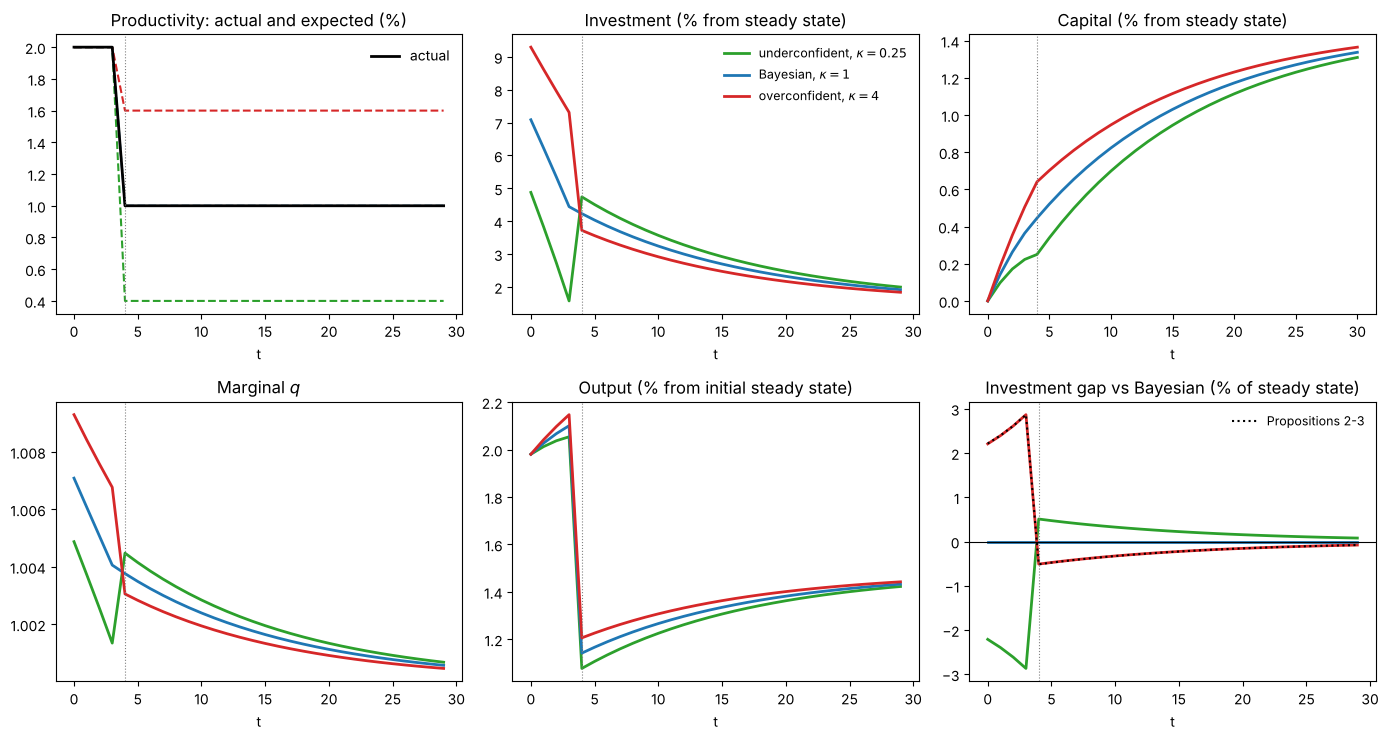

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
H = 30
t = np.arange(H)
labels = {0.25: r'underconfident, $\kappa = 0.25$', 1.0: r'Bayesian, $\kappa = 1$', 4.0: r'overconfident, $\kappa = 4$'}
colors = {0.25: 'C2', 1.0: 'C0', 4.0: 'C3'}
for kap, p in paths.items():
    col = colors[kap]
    axes[0, 0].plot(t, 100 * (p['A_belief'][:H] - 1), color=col, ls='--', lw=1.5)
    axes[0, 1].plot(t, 100 * (p['I'][:H] / I_ss - 1), color=col, lw=2, label=labels[kap])
    axes[0, 2].plot(np.arange(H + 1), 100 * np.log(p['k'][:H + 1] / f.k_ss), color=col, lw=2)
    axes[1, 0].plot(t, p['q'][:H], color=col, lw=2)
    axes[1, 1].plot(t, 100 * np.log(p['Y'][:H] / p['Y'][0] * (1 + info.x)), color=col, lw=2)
    axes[1, 2].plot(t, 100 * (p['I'][:H] - paths[1.0]['I'][:H]) / I_ss, color=col, lw=2)
axes[0, 0].plot(t, 100 * (paths[1.0]['A'][:H] - 1), color='k', lw=2, label='actual')
axes[0, 0].legend(frameon=False)
titles = ['Productivity: actual and expected (%)', 'Investment (% from steady state)', 'Capital (% from steady state)',
          r'Marginal $q$', 'Output (% from initial steady state)', 'Investment gap vs Bayesian (% of steady state)']
for ax, ti in zip(axes.flat, titles):
    ax.set_title(ti)
    ax.axvline(info.tau, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('t')
axes[0, 1].legend(frameon=False, fontsize=9)
axes[1, 2].axhline(0, color='k', lw=0.8)
dk_lin, dI_lin = linear_gap(4.0, info, f)
axes[1, 2].plot(t, 100 * dI_lin[:H], 'k:', lw=1.5, label='Propositions 2-3')
axes[1, 2].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Two features are worth noticing.

- **Output barely differs.** A small gap in the capital stock moves output by a fraction $\alpha$ of itself. The mistake shows up much more in investment, which is a flow out of a large stock, than in output.
- **The gap grows until $\tau$.** Investment falls during the boom for every manager, because the transitory part of the productivity gain is about to end. But as Proposition 2 says, the overconfident manager's investment pulls further away from the Bayesian's as the date at which it expects the extra permanent productivity gets closer. This is why the reversal at $\tau$ is sharp.

## Who loses

### Three measures

Under the true productivity path, three present values summarise the outcome:

- **shareholder value** $V = \sum_t (1+r)^{-t} d_t$, the dividends the firm actually pays,
- **workers' income** $\sum_t (1+r)^{-t} w_t \bar n$, and
- **national wealth** $W = \sum_t (1+r)^{-t} (Y_t - I_t - AC_t)$, their sum.

In a small open economy with access to world credit markets at rate $r$, households can spread $W$ over time however they like, so $W$ is the right measure of welfare. A household that consumes a constant amount gets $c = \frac{r}{1+r} W$ per year, so a change in $W$ translates into a permanent change in consumption of $\frac{r}{1+r}\Delta W$.

### An envelope argument

The Bayesian's plan maximises $W$ given the information available. To see why, note that the firm's Euler equation sets $\partial Y_{t+1}/\partial k_{t+1}$ equal to the cost of capital including adjustment costs. That is exactly the first-order condition for maximising $W$ over the capital path, since with labour fixed, $\partial Y/\partial k$ is the only effect of capital on output. The firm treats the wage as given, but because the wage it pays is income to workers, the wage effect cancels out of $W$.

So at the Bayesian plan, $\partial W / \partial \hat m = 0$, and

**Proposition 4 (first-order transfers, second-order losses).** To second order in $\hat m - m$,

$$
\boxed{\;W(\hat m) - W(m) \approx -\tfrac{1}{2}\, \mathcal{H}\, (\hat m - m)^2, \qquad V(\hat m) - V(m) \approx -\mathcal{T}\, (\hat m - m)\;}
$$

for positive constants $\mathcal{H}$ and $\mathcal{T}$. The efficiency loss is second order: small mistakes cost little. The **redistribution** between shareholders and workers is first order. Overinvestment raises the capital stock, which raises the marginal product of labour and the wage. Workers gain, and shareholders lose more than workers gain. Underinvestment does the reverse, and shareholders gain at workers' expense, although the economy as a whole still loses.

This mirrors Proposition 1 of Lecture 7: the cost of misweighting a signal was quadratic in $\hat w - w$, and it is quadratic here too.

### Averaging over outcomes

So far the true permanent change has equalled the Bayesian's forecast. More generally, $\theta$ could be anything consistent with the information, $\theta \mid x \sim N(m, v)$. Expected national wealth is then

$$
\mathbb{E}\left[W(\hat m, \theta)\right] = \int W(\hat m, \theta)\, \phi\!\left(\frac{\theta - m}{\sqrt v}\right) \frac{d\theta}{\sqrt v}
$$

In the linear-quadratic approximation, **certainty equivalence** holds: the plan before $\tau$ depends only on the expected value of $\theta$, the re-plan after $\tau$ is the same for both managers given $\theta$, and the expected loss equals the loss when $\theta = m$. We check this with Gauss–Hermite quadrature over $\theta$, re-planning from $k_\tau$ at each node.

In [7]:
def welfare_table(info, f, kappas=(0.25, 0.5, 1.0, 2.0, 4.0)):
    base = outcomes(temporary_equilibrium(1.0, info, f), f)
    w, _ = weights(1.0, info)
    rows = []
    for kap in kappas:
        p = outcomes(temporary_equilibrium(kap, info, f), f)
        dm = (p['w_hat'] - w) * info.x
        rows.append((kap, dm, p['W'] - base['W'], p['V'] - base['V'], p['PV_wages'] - base['PV_wages']))
    return rows


def c_equiv(dW, f, info):
    # permanent consumption change as % of steady-state consumption in the small open economy
    c_ss = f.k_ss ** f.alpha * f.n_bar ** (1 - f.alpha) - f.delta * f.k_ss
    return 100 * f.r / (1 + f.r) * dW / c_ss


rows = welfare_table(info, f)
print(f"{'kappa':>6} {'m_hat - m':>10} {'dW':>11} {'dW/(dm)^2':>10} {'dV':>10} {'dV/dm':>8} {'d wages':>10} {'cons. equiv. (%)':>17}")
for kap, dm, dW, dV, dwage in rows:
    ratio_W = dW / dm ** 2 if dm != 0 else np.nan
    ratio_V = dV / dm if dm != 0 else np.nan
    print(f'{kap:6.2f} {100 * dm:9.2f}% {dW:11.2e} {ratio_W:10.4f} {dV:10.5f} {ratio_V:8.4f} {dwage:10.5f} {c_equiv(dW, f, info):17.5f}')

 kappa  m_hat - m          dW  dW/(dm)^2         dV    dV/dm    d wages  cons. equiv. (%)
  0.25     -0.60%   -9.34e-06    -0.2595    0.00249  -0.4143   -0.00250          -0.00007
  0.50     -0.33%   -2.88e-06    -0.2594    0.00138  -0.4149   -0.00139          -0.00002
  1.00      0.00%    0.00e+00        nan    0.00000      nan    0.00000           0.00000
  2.00      0.33%   -2.88e-06    -0.2590   -0.00139  -0.4162    0.00138          -0.00002
  4.00      0.60%   -9.32e-06    -0.2589   -0.00250  -0.4168    0.00249          -0.00007


In [8]:
def expected_W(kappa, info, f, n_nodes=9):
    # E[W] over theta | x ~ N(m, v) by Gauss-Hermite quadrature, re-planning at tau for each theta.
    w, _ = weights(kappa, info)
    sigma_T2 = 0.02 ** 2                       # sigma_P = sigma_T = 2%, so varrho = 1
    sigma_P2 = info.varrho * sigma_T2
    m, v = w * info.x, sigma_P2 * sigma_T2 / (sigma_P2 + sigma_T2)
    nodes, wts = np.polynomial.hermite_e.hermegauss(n_nodes)
    vals = [outcomes(temporary_equilibrium(kappa, info, f, theta=m + np.sqrt(v) * z), f)['W'] for z in nodes]
    return wts @ np.array(vals) / wts.sum()


EW1 = expected_W(1.0, info, f)
print(f"{'kappa':>6} {'E[dW] over theta':>18} {'dW at theta = m':>16}")
for kap in [0.25, 4.0]:
    EW = expected_W(kap, info, f)
    dW_m = [r_ for r_ in rows if r_[0] == kap][0][2]
    print(f'{kap:6.2f} {EW - EW1:18.3e} {dW_m:16.3e}')

 kappa   E[dW] over theta  dW at theta = m


  0.25         -9.316e-06       -9.343e-06


  4.00         -9.346e-06       -9.319e-06


The columns $\Delta W/(\Delta m)^2$ and $\Delta V/\Delta m$ are close to constant across $\kappa$, as Proposition 4 says, with the small remaining variation coming from the third-order terms the approximation drops. National wealth falls for every manager except the Bayesian, symmetrically for over- and underconfidence. Shareholder value moves in the opposite direction to the capital stock, and workers' income moves with it.

The quadrature confirms certainty equivalence: the expected loss over all values of the permanent shock is essentially the loss at $\theta = m$.

The aggregate welfare cost is small, a tiny fraction of a percent of consumption, because it is second order in a 2% shock. The redistribution between shareholders and workers is two orders of magnitude larger. The costs grow with the square of the shock, so they matter more for large shocks, such as a technology whose permanence is genuinely uncertain, or a sector-specific boom where $x$ is much larger than 2%. The exercises ask you to check this.

## When everyone is overconfident

### Back to the closed economy

The small open economy fixed the interest rate, so only the manager's beliefs mattered. In the closed economy of [Lecture 2](02_adjustment_costs.ipynb), saving must equal investment, the real interest rate is determined in the market, and labour supply responds. What happens if **all** agents, households as well as firms, read the jump as more permanent than it is?

Common beliefs keep the analysis simple: with everyone sharing the belief $\hat A$, the decentralised equilibrium under those beliefs is the one the price system of Lecture 2 computes, with $A$ replaced by the expected path. The temporary-equilibrium method is unchanged: solve under beliefs from date $0$, act until $\tau$, re-solve from $(k_\tau, n_{\tau - 1})$ under the truth.

The code below collects the price system from Lecture 2 unchanged. The only modifications are that productivity can be a path, and the solve can start from any $(k_0, n_{-1})$ and end at the steady state for the final productivity level.

In [9]:
LabSettings = namedtuple('LabSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'zeta',
                                         'zeta_n', 'H', 'a', 'n0', 'k_ss', 'n_ss', 'c_ss'])


def get_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                 zeta=5.0, zeta_n=2.0, H=1.0, n_target=1 / 3):
    # Steady state has employment n_ss = n_target * H; the consumption weight a is calibrated to deliver it.
    kappa = ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))      # k/n in steady state
    y_n = A * kappa ** alpha
    c_n = y_n - delta * kappa
    w_ss = (1 - alpha) * y_n
    n_ss = n_target * H
    a = 1 / (1 + (H - n_ss) / n_ss * w_ss / c_n)
    k_ss, c_ss = kappa * n_ss, c_n * n_ss
    return LabSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, zeta, zeta_n, H, a, n_ss, k_ss, n_ss, c_ss)


# ----- capital adjustment costs (same functional forms as adjustment_cost / adjust_cost_t /
# adjust_cost_t1 in cge_lucas.py, with trend growth = 0, in 1D). k = (k_0..k_{T+1}), g_t = k_{t+1}/k_t.
def adjustment_cost(k, s):
    """AC_t = zeta k_t/2 (k_{t+1}/k_t - 1)^2, paid in goods; t = 0..T."""
    return s.zeta * k[:-1] / 2 * (k[1:] / k[:-1] - 1) ** 2


def adjust_cost_t(k, s):
    """dAC_t/dk_{t+1} = zeta (g_t - 1): extra cost of installing capital at t."""
    return s.zeta * (k[1:] / k[:-1] - 1)


def adjust_cost_t1(k, s):
    """dAC_{t+1}/dk_{t+1} = zeta/2 (1 - g_{t+1}^2): adjustment cost saved next period by having more capital."""
    return s.zeta / 2 * (1 - (k[1:] / k[:-1]) ** 2)


# ----- labour adjustment costs;  n_ext = (n_{-1}, n_0..n_T),  outputs indexed t = 0..T -----
def labour_adj_cost(n_ext, s):
    return s.zeta_n * n_ext[1:] / 2 * (n_ext[1:] / n_ext[:-1] - 1) ** 2


def labour_adj_cost_prime_t(n_ext, s):
    # dLAC_t / dn_t
    g = n_ext[1:] / n_ext[:-1]
    return s.zeta_n / 2 * (g - 1) ** 2 + s.zeta_n * g * (g - 1)


def labour_adj_cost_prime_t1(n_ext, s):
    # dLAC_t / dn_{t-1}  (what the firm saves one period earlier by having more labour at t-1)
    g = n_ext[1:] / n_ext[:-1]
    return -s.zeta_n * (g - 1) * g ** 2


def lead(z):
    # z_{t+1}, with z_{T+1} = 0 (no labour adjustment after T)
    return jnp.concatenate([z[1:], jnp.zeros(1)])


def MLAC(n_ext, p_y, s, r):
    # Marginal labour adjustment cost: p_t dLAC_t/dn_t + p_{t+1}/(1+r) dLAC_{t+1}/dn_t
    p_next = jnp.concatenate([p_y[1:], p_y[-1:]])
    return (p_y * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + r))


def unpack(x, s):
    T, n = s.T, s.T + 1
    p_y = jnp.concatenate([jnp.ones(1), jnp.exp(x[:T])])             # numeraire: p_y_0 = 1
    w, u, y, nl = (jnp.exp(x[T + i * n:T + (i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 4 * n:]), jnp.array([s.k_ss])])   # k_0..k_{T+1}
    return p_y, w, u, y, nl, k


def price_block(p_y, w, u, y, nl, k, s, r):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = MLAC(n_ext, p_y, s, r)

    y_bt = y + ac + lac                                      # gross output produced
    p_n = w + mlac                                           # price of labour input (wage + shadow adjustment cost)
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)               # marginal cost
    p_ks = p_y_bt * s.alpha * y_bt / ks                      # capital services price
    p_c = p_y
    p_i = p_y

    # household static problem (Cobb-Douglas consumption-leisure)
    p_l = w
    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    N_supply = s.H - leisure

    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p_y * s.zeta * (invest / ks - s.delta)         # shadow price of installed capital
    return dict(ac=ac, lac=lac, mlac=mlac, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, p_c=p_c, p_i=p_i,
                p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=N_supply, I=invest, q=q)


def transition_economy(x, s, solving=1):
    p_y, w, u, y, nl, k = unpack(x, s)
    r = 1 / s.beta - 1
    P = price_block(p_y, w, u, y, nl, k, s, r)

    price_error = (p_y - P['p_y_bt']) / p_y
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * (1 + r) * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p_y[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - r

    errors = jnp.concatenate([price_error, production_error, labour_error, goods_error,
                              household_error, capital_error])
    if solving:
        return errors

    div = P['p_ks'] * k[:-1] + P['mlac'] * nl - p_y * (P['ac'] + P['lac']) - P['p_i'] * P['I']
    budget = P['p_c'] * P['c'] - (w * nl + div)                    # Walras check, should be ~0
    econ = dict(P, p_y=p_y, w=w, u=u, y=y, n=nl, k=k, div=div, budget=budget, r=r,
                tobin_q=q / P['p_i'], real_w=w / P['p_c'], real_ks=P['p_ks'] / P['p_c'],
                r_real=(1 + r) * p_y[:-1] / p_y[1:] - 1)
    return errors, econ

In [10]:
def solve_closed(s_base, A_path, k0, n_prev):
    # Solve the price system of Lecture 2 for a productivity path, from (k0, n_{-1}).
    A_end = float(A_path[-1])
    k_end = s_base.k_ss * (A_end / s_base.A) ** (1 / (1 - s_base.alpha))   # steady-state employment is unchanged
    s = s_base._replace(A=jnp.asarray(A_path), k0=k0, n0=n_prev, k_ss=k_end)
    n = s.T + 1
    n_ss = s_base.n_ss
    y_ss = A_end * (k_end / n_ss) ** s.alpha * n_ss
    w_ss = (1 - s.alpha) * y_ss / n_ss
    c_ss = y_ss - s.delta * k_end
    u_ss = c_ss ** s.a * (s.H - n_ss) ** (1 - s.a)
    k_path = np.linspace(k0, k_end, s.T + 2)[1:-1]
    x0 = np.log(np.hstack((np.ones(s.T), w_ss * np.ones(n), u_ss * np.ones(n), y_ss * np.ones(n),
                           n_ss * np.ones(n), k_path)))
    resid = lambda x: transition_economy(x, s, 1)
    x1 = newton(resid, x0, tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(resid, x1, tol=1e-12, max_iter=100)
    errors, econ = transition_economy(x, s, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    econ['residual'] = float(jnp.max(jnp.abs(errors)))
    return econ


def closed_temporary_equilibrium(kappa, info, s_base):
    w, w_hat = weights(kappa, info)
    n = s_base.T + 1
    A_belief = productivity(info.x, w_hat * info.x, n, info.tau)
    A_true = productivity(info.x, w * info.x, n + info.tau, info.tau)
    plan = solve_closed(s_base, A_belief, s_base.k_ss, s_base.n_ss)
    tau = info.tau
    after = solve_closed(s_base, A_true[tau:tau + n], plan['k'][tau], plan['n'][tau - 1])
    keys = ['c', 'n', 'I', 'k', 'r_real', 'y', 'tobin_q']
    out = {k_: np.concatenate([plan[k_][:tau], after[k_]]) for k_ in keys}
    out['residual'] = max(plan['residual'], after['residual'])
    return out


s_closed = get_settings(T=150, k0_frac=1.0)
closed = {kap: closed_temporary_equilibrium(kap, info, s_closed) for kap in [1.0, 4.0]}
I_ss_c = s_closed.delta * s_closed.k_ss
for kap, e in closed.items():
    print(f'kappa = {kap}: max |residual| = {e["residual"]:.1e}')
    print(f'   investment (% from ss), t = 0..7:  {np.round(100 * (e["I"][:8] / I_ss_c - 1), 2)}')
    print(f'   consumption (% from ss), t = 0..7: {np.round(100 * (e["c"][:8] / s_closed.c_ss - 1), 2)}')

kappa = 1.0: max |residual| = 3.1e-15
   investment (% from ss), t = 0..7:  [8.93 9.3  9.44 9.41 2.78 2.54 2.43 2.35]
   consumption (% from ss), t = 0..7: [1.51 1.62 1.69 1.72 1.22 1.21 1.21 1.22]
kappa = 4.0: max |residual| = 4.1e-15
   investment (% from ss), t = 0..7:  [7.39 7.57 7.59 7.51 2.87 2.67 2.57 2.5 ]
   consumption (% from ss), t = 0..7: [1.62 1.72 1.78 1.83 1.15 1.15 1.16 1.17]


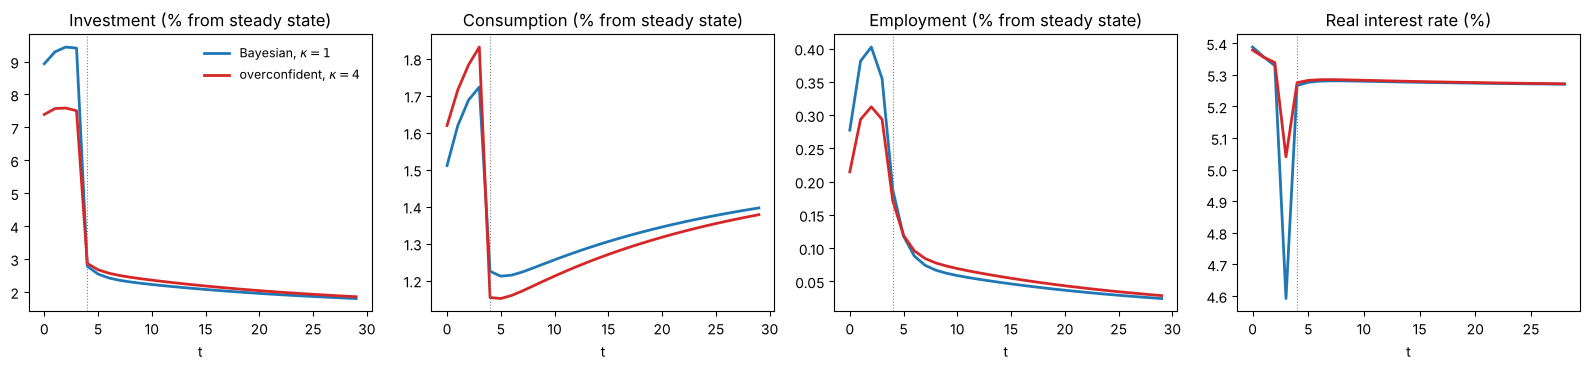

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
H = 30
t = np.arange(H)
for kap, e in closed.items():
    col = colors[kap]
    lab = labels[kap]
    axes[0].plot(t, 100 * (e['I'][:H] / I_ss_c - 1), color=col, lw=2, label=lab)
    axes[1].plot(t, 100 * (e['c'][:H] / s_closed.c_ss - 1), color=col, lw=2)
    axes[2].plot(t, 100 * (e['n'][:H] / s_closed.n_ss - 1), color=col, lw=2)
    axes[3].plot(t[:H - 1], 100 * e['r_real'][:H - 1], color=col, lw=2)
for ax, ti in zip(axes, ['Investment (% from steady state)', 'Consumption (% from steady state)',
                         'Employment (% from steady state)', 'Real interest rate (%)']):
    ax.set_title(ti)
    ax.axvline(info.tau, color='grey', lw=0.8, ls=':')
    ax.set_xlabel('t')
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### Why the boom disappears

In the closed economy with common beliefs, overconfidence **lowers** investment during the boom and raises consumption. The reason is the household's **wealth effect**.

- **Permanent income.** Households smooth consumption: they spend most of a permanent rise in income and save most of a temporary one. Households who read more of the jump as permanent see less of it as temporary, so they save less of it and consume more. They also feel richer, so they work less, which lowers output.
- **Saving is investment.** In a closed economy, investment can only be what output leaves after consumption. With consumption higher and employment lower, investment has to fall.
- **The price that does it is the real interest rate over the boom.** Bayesian households expect a large part of the gain to end at $\tau$, so they expect consumption to fall then and are keen to save beforehand. That drives the real interest rate between $t = 3$ and $t = 4$ down to about 4.6%. Overconfident households expect a smaller fall in consumption, so the rate in that year only falls to about 5.0%. The higher discount rate over the boom lowers the firm's marginal $q$, even though the firm expects a higher marginal product of capital after $\tau$, and the firm invests less.

The code below prints the real rates and $q$ during the boom, when the plan is still being followed, to confirm this.

In [12]:
plain = {1.0: 'Bayesian (kappa = 1)', 4.0: 'overconfident (kappa = 4)'}
print(f"{'':32s}{'t = 0':>8}{'t = 1':>8}{'t = 2':>8}{'t = 3':>8}")
for kap, e in closed.items():
    print(f'{plain[kap]:32s}' + ''.join(f'{100 * v:8.2f}' for v in e['r_real'][:4]) + '   real rate (%)')
    print(f'{"":32s}' + ''.join(f'{v:8.4f}' for v in e['tobin_q'][:4]) + '   marginal q')

                                   t = 0   t = 1   t = 2   t = 3
Bayesian (kappa = 1)                5.39    5.36    5.33    4.59   real rate (%)
                                  1.0089  1.0091  1.0090  1.0088   marginal q
overconfident (kappa = 4)           5.38    5.36    5.34    5.04   real rate (%)
                                  1.0074  1.0074  1.0073  1.0070   marginal q


The overconfident economy therefore has a **consumption** boom rather than an investment boom, and at $\tau$, when households learn they are poorer than they thought, consumption falls. The reversal is still there; it has moved from investment to consumption.

### Who holds the belief matters

The two parts of this lecture apply the same distortion, $\kappa = 4$, to the same signal and the same technology, and get opposite investment responses. What differs is **who** is overconfident and what disciplines them:

- with overconfident **managers** and correct financial markets, the interest rate is set by agents who are not overconfident, so the manager's beliefs flow straight into investment, as in Malmendier and Tate's evidence;
- with overconfidence **everywhere**, it also distorts the saving decision, and general-equilibrium price movements reverse the partial-equilibrium intuition.

This is a recurring theme in behavioural macroeconomics. A bias documented in individual decisions does not translate mechanically into aggregate outcomes. The answer depends on which agents hold it and on how prices respond.

## Summary

| | Small open economy, overconfident manager | Closed economy, overconfident everyone |
|---|---|---|
| Before the truth is revealed | investment boom, capital overshoots | consumption boom, lower employment and investment, higher real rates over the boom |
| After | investment bust while excess capital runs down | consumption falls back |
| Closed forms | Propositions 1–3 (linear q-theory) | none here; solved numerically |
| Welfare | second-order loss; first-order transfer from shareholders to workers | |

## Exercises

1. **Adjustment costs.** Use Proposition 2 to show that the overinvestment gap at $\tau$ falls as $\zeta$ rises. Check it numerically for $\zeta \in \{2, 5, 20\}$. Is the bust larger or smaller with higher adjustment costs? Use Proposition 3 to find the value of $\zeta$ at which $\mu = 1 - \delta$.
2. **Larger shocks.** Repeat the welfare table with $x = 10\%$. Check that $\Delta W$ scales with $x^2$ and $\Delta V$ with $x$.
3. **A surprise in the other direction.** Set $\theta = 0$: the whole jump was transitory. Compare the Bayesian's and the overconfident manager's paths. Which bust is larger, and why?
4. **Heterogeneous beliefs in a closed economy.** Suppose firms are overconfident but households are Bayesian, in the closed economy. Write down the temporary equilibrium at date $t$. What does each agent need to forecast, and why is this harder to solve than either part of this lecture?
5. **Learning over time.** Instead of learning everything at $\tau$, suppose the firm observes productivity each year with noise, and updates by the Kalman filter. Overconfidence is now $\kappa > 1$ on each year's observation. Simulate the boom and compare it with the one-shot revelation here.

## References

- Ben-David, I., Graham, J. R. and Harvey, C. R. (2013). Managerial miscalibration. *Quarterly Journal of Economics*, 128(4), 1547–1584.
- Gennaioli, N., Ma, Y. and Shleifer, A. (2016). Expectations and investment. *NBER Macroeconomics Annual*, 30, 379–431.
- Grandmont, J.-M. (1977). Temporary general equilibrium theory. *Econometrica*, 45(3), 535–572.
- Hayashi, F. (1982). Tobin's marginal q and average q: a neoclassical interpretation. *Econometrica*, 50(1), 213–224.
- Malmendier, U. and Tate, G. (2005). CEO overconfidence and corporate investment. *Journal of Finance*, 60(6), 2661–2700.
- Malmendier, U. and Tate, G. (2008). Who makes acquisitions? CEO overconfidence and the market's reaction. *Journal of Financial Economics*, 89(1), 20–43.
- Odean, T. (1998). Volume, volatility, price, and profit when all traders are above average. *Journal of Finance*, 53(6), 1887–1934.